# RQ4 pipeline, step 2: k-means and Louvain groups in the co-listening graph

## Question
`RQ4_extension/01` showed that the k-means pseudo-genres are visible in **how people listen**: on a graph that links tracks played in the same session, far more link weight lies inside pseudo-genres than chance would put there (modularity 0.52 at k = 32), and most of it survives removing same-artist and same-album links.
This notebook asks the same of the **Louvain** sound groups, side by side with k-means, and adds two things that notebook could not do:

1. **Do Louvain sound groups follow listening as well as, better or worse than k-means pseudo-genres?** Same graph, same controls, same graph sizes.
2. **An upper reference.** `RQ4_extension/01` noted that it could not say how much of the listening structure the pseudo-genres capture, because the best possible modularity was unknown. We now have a Louvain implementation, so we run it **on the co-listening graph itself**. Its modularity is (close to) the best any partition of this graph reaches, and its communities are "genres from behaviour" found without any audio.
3. **The briefing's Method B.** The team briefing described Method B as Louvain on a *co-listening* graph, while Peter built it on the audio graph. Running it on the co-listening graph covers the original plan and lets us compare all three partitions.

| § | Content |
|---|---|
| 1 | Data and the co-listening graph (identical to `RQ4_extension/01`) |
| 2 | Modularity of the sound partitions: Louvain vs k-means |
| 3 | Controls: without same-artist and same-album links |
| 4 | Graph size |
| 5 | Louvain on the co-listening graph: upper reference and agreement with the sound partitions |
| 6 | Summary |

**Stream rule.** As everywhere: each (user, track) belongs to the stream of the user's first real listen of it; tracks played in the user's first 60 days are excluded (`scripts/streams.py`). The graph uses tracks users found **organically**, as in `RQ4_extension/01`.

*Prerequisites:* `RQ4_pipeline/louvain_groups.csv.gz` (notebook 00), raw Yambda-50M events and mappings, `data/processed/emb50m_*.npy`. Run time: about 5 minutes. Memory: about 5 GB at the peak (reading all listens).

## 0. Setup and parameters

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components

# ---------------- parameters (change here, then Run All) ----------------
STREAM_MODE, WARMUP_DAYS, REAL_PCT = "discovery", 60, 50
SESSION_GAP_S = 30 * 60
BASKET_CAP, MAX_BASKETS_PER_USER = 15, 50
N_NODES_LIST = [10_000, 20_000, 40_000]
N_MAIN = 20_000
MIN_COUNT, K_NN = 3, 20                  # graph settings of RQ4_extension/01
N_SEEDS_KM = 3; N_FIT = 150_000
N_SHUFFLE = 20
LISTEN_SEEDS = [0, 1, 2]                 # Louvain runs on the co-listening graph
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC, KM = "#264653", "#9aa0a6", "#e76f51", "#e9c46a"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import louvain as LV
from streams import stream_labels
from rq4_tools import kmeans_grid, nmi, item_map, read_listens, graph_from_csr, modularity_sparse
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_pipeline"
ari = LV.adjusted_rand_index
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Data, partitions and the co-listening graph
The graph is built with exactly the code and settings of `RQ4_extension/01` (organic real listens, sessions split at 30-minute gaps, at most 15 tracks per session and 50 sessions per user,
an edge needs 3 shared sessions, weights normalised by the square root of the two tracks' session counts, 20 strongest neighbours per track, largest connected component).

**Sound partitions on the graph's tracks:** Louvain (five seeds; tracks outside Peter's 50,000 get the group of their nearest graph tracks, notebook 00), the project's k-means file (k = 32), and k-means with k equal to the number of Louvain groups (three starts), so that the two methods are also compared at the **same number of groups**. Modularity falls as the number of groups grows, so comparisons at different numbers of groups need the chance-corrected view as well.

In [2]:
t0 = time.time()
uid_r, item_r, ts_r, lab_r = read_listens(DATA, REAL_PCT, STREAM_MODE, WARMUP_DAYS, stream_labels)
keep = lab_r == 1                                                       # organic stream only
uid, item, ts = uid_r[keep].astype(np.int64), item_r[keep].astype(np.int64), ts_r[keep].astype(np.int64)
del uid_r, item_r, ts_r, lab_r, keep
print(f"{len(uid):,} organic real listens of {len(np.unique(uid)):,} users ({time.time() - t0:.0f} s)")

emb_ids = np.load(PROC / "emb50m_item_ids.npy")
L = int(max(item.max(), emb_ids.max())) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids))
new_sess = np.r_[True, uid[1:] != uid[:-1]] | np.r_[True, (ts[1:] - ts[:-1]) > SESSION_GAP_S]
sid = np.cumsum(new_sess) - 1
pair = np.unique(uid * (1 << 32) + item)
users_per_item = np.bincount(pair & 0xFFFFFFFF, minlength=L); del pair
cand = np.flatnonzero((item_row >= 0) & (users_per_item > 0))
item_art = item_map(DATA / "artist_item_mapping.parquet", "artist_id", L)
item_alb = item_map(DATA / "album_item_mapping.parquet", "album_id", L)

grp = pd.read_csv(OUT / "louvain_groups.csv.gz"); assert np.array_equal(grp["item_id"].to_numpy(), emb_ids)
LSEEDS = [int(c.split("_s")[1]) for c in grp.columns if c.startswith("louvain_s")]
in_graph_sound = grp["in_graph"].to_numpy()
K_MATCH = int(grp.loc[in_graph_sound, "louvain_s0"].max()) + 1
EN = np.load(PROC / "emb50m_norm.npy")
km = kmeans_grid(EN, [K_MATCH, 32], N_SEEDS_KM, N_FIT, SEED); del EN
km_file = pd.read_csv(ROOT / "RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz").set_index("item_id")["kmeans_cluster"].reindex(emb_ids).to_numpy()
# every partition as a list of label arrays over embedding rows (several runs where available)
PARTS = {"Louvain (sound graph)": [grp[f"louvain_s{s}"].to_numpy() for s in LSEEDS],
         "k-means project file (k = 32)": [km_file],
         "k-means, k = 32 (3 starts)": [km[(32, s)] for s in range(N_SEEDS_KM)],
         f"k-means, k = {K_MATCH} (3 starts)": [km[(K_MATCH, s)] for s in range(N_SEEDS_KM)]}
print(f"partitions ready; Louvain seed 0 has {K_MATCH} groups ({time.time() - t0:.0f} s)")

5,417,474 organic real listens of 7,702 users (18 s)


partitions ready; Louvain seed 0 has 28 groups (46 s)


In [3]:
def rank_in_sorted_groups(g):
    start = np.r_[0, np.flatnonzero(g[1:] != g[:-1]) + 1]
    return np.arange(len(g)) - np.repeat(start, np.diff(np.r_[start, len(g)]))

def build_graph(n_nodes):          # unchanged from RQ4_extension/01
    top = cand[np.argsort(-users_per_item[cand], kind="stable")[:n_nodes]]
    node_of_item = np.full(L, -1, dtype=np.int64); node_of_item[top] = np.arange(len(top))
    nd = node_of_item[item]; m = nd >= 0
    s_, n_, u_ = sid[m], nd[m], uid[m]
    _, first = np.unique(s_ * len(top) + n_, return_index=True); first.sort()
    s_, n_, u_ = s_[first], n_[first], u_[first]
    keep = rank_in_sorted_groups(s_) < BASKET_CAP
    s_, n_, u_ = s_[keep], n_[keep], u_[keep]
    _, binv, bcnt = np.unique(s_, return_inverse=True, return_counts=True)
    b_user = u_[np.r_[0, np.cumsum(bcnt)[:-1]]]
    ok2 = bcnt >= 2
    rk_u = np.full(len(bcnt), 10 ** 9); rk_u[ok2] = rank_in_sorted_groups(b_user[ok2])
    ent = (ok2 & (rk_u < MAX_BASKETS_PER_USER))[binv]
    rows = np.unique(binv[ent], return_inverse=True)[1]; cols = n_[ent]
    S = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(rows.max() + 1, len(top)))
    Cc = (S.T @ S).tocsr(); b = Cc.diagonal().copy(); Cc.setdiag(0); Cc.eliminate_zeros()
    Cc.data[Cc.data < MIN_COUNT] = 0; Cc.eliminate_zeros()
    co = Cc.tocoo(); w = co.data / np.sqrt(b[co.row] * b[co.col])
    o = np.lexsort((-w, co.row)); r_o, c_o, w_o = co.row[o], co.col[o], w[o]
    kk = rank_in_sorted_groups(r_o) < K_NN
    Wk = sparse.coo_matrix((w_o[kk], (r_o[kk], c_o[kk])), shape=Cc.shape).tocsr()
    A_full = Wk.maximum(Wk.T).tocsr()
    ncomp, comp = connected_components(A_full, directed=False)
    lcc = np.flatnonzero(comp == np.argmax(np.bincount(comp)))
    A = A_full[lcc][:, lcc].tocsr(); node_item = top[lcc]
    return dict(A=A, node_item=node_item, node_row=item_row[node_item])

graphs = {n_: build_graph(n_) for n_ in N_NODES_LIST}
G = graphs[N_MAIN]; A, node_item, node_row = G["A"], G["node_item"], G["node_row"]
for n_, g_ in graphs.items():
    print(f"{n_:>6,} candidate tracks: {g_['A'].shape[0]:,} nodes, {g_['A'].nnz // 2:,} edges; "
          f"{in_graph_sound[g_['node_row']].mean():.0%} of the nodes are among Louvain's 50,000 sound-graph tracks")

10,000 candidate tracks: 9,862 nodes, 97,535 edges; 98% of the nodes are among Louvain's 50,000 sound-graph tracks
20,000 candidate tracks: 18,484 nodes, 145,955 edges; 92% of the nodes are among Louvain's 50,000 sound-graph tracks
40,000 candidate tracks: 29,316 nodes, 186,481 edges; 81% of the nodes are among Louvain's 50,000 sound-graph tracks


## 2. Modularity of the sound partitions on the co-listening graph
For a partition, **modularity** Q is the share of link weight inside groups minus the share random wiring with the same degrees would put there (0 = no better than random labels).
Q falls when the number of groups rises, so we also report the **ratio to chance** (inside share divided by the share expected by chance) and compare k-means at the same number of groups as Louvain.
The chance level is the same partition with shuffled labels (20 shuffles).

In [4]:
def inside_expected(Am, lab):
    _, lab = np.unique(lab, return_inverse=True); k = lab.max() + 1
    M = sparse.csr_matrix((np.ones(len(lab)), (np.arange(len(lab)), lab)), shape=(len(lab), k))
    B = (M.T @ Am @ M).toarray(); tot = B.sum()
    return np.trace(B) / tot, ((B.sum(1) / tot) ** 2).sum()

def evaluate(Am, rows_, graph_label, variant):
    out = []
    for name, runs in PARTS.items():
        for s, lab_all in enumerate(runs):
            lab = lab_all[rows_]; ins, exp_ = inside_expected(Am, lab)
            sh = [np.subtract(*inside_expected(Am, rng.permutation(lab))) for _ in range(N_SHUFFLE if s == 0 else 3)]
            out.append(dict(graph=graph_label, variant=variant, partition=name, run=s, groups=len(np.unique(lab)), Q=ins - exp_, inside=ins, expected=exp_,
                            ratio_to_chance=ins / exp_, Q_shuffled=np.mean(sh)))
    return out

res = pd.DataFrame(evaluate(A, node_row, N_MAIN, "all edges"))
tab = res.groupby("partition", sort=False).agg(groups=("groups", "mean"), Q=("Q", "mean"), Q_sd=("Q", "std"), inside=("inside", "mean"), expected=("expected", "mean"),
                                               ratio_to_chance=("ratio_to_chance", "mean"), Q_shuffled=("Q_shuffled", "mean"))
print(f"main graph ({A.shape[0]:,} tracks), all edges; mean over runs:"); print(tab.to_string(float_format=lambda x: f"{x:.3f}"))

main graph (18,484 tracks), all edges; mean over runs:
                               groups     Q  Q_sd  inside  expected  ratio_to_chance  Q_shuffled
partition                                                                                       
Louvain (sound graph)          27.200 0.583 0.002   0.640     0.057           11.255      -0.000
k-means project file (k = 32)  32.000 0.512   NaN   0.566     0.054           10.479      -0.000
k-means, k = 32 (3 starts)     32.000 0.521 0.007   0.566     0.046           12.468      -0.000
k-means, k = 28 (3 starts)     28.000 0.523 0.003   0.576     0.053           10.935       0.000


### 2.1 Reading the modularity

**Both sound partitions follow listening far more than chance, and Louvain groups follow it more than k-means pseudo-genres.** On the main graph (18,484 tracks, 92% of them Louvain graph tracks):

| Partition | groups | Q | share of link weight inside groups | expected by chance | ratio to chance |
|---|---|---|---|---|---|
| Louvain (5 seeds) | 27.2 | **0.583** | 64.0% | 5.7% | 11.3 |
| k-means, k = 28 (3 starts) | 28 | 0.523 | 57.6% | 5.3% | 10.9 |
| k-means, k = 32 (3 starts) | 32 | 0.521 | 56.6% | 4.6% | 12.5 |
| k-means project file | 32 | 0.512 | 56.6% | 5.4% | 10.5 |

Shuffled labels give 0.000 for all. At the same number of groups, Louvain puts 64% of the co-listening weight inside its groups against 58% for k-means (Q 0.58 against 0.52, spread over runs 0.002 to 0.007). The k = 32 value for k-means reproduces `RQ4_extension/01` (0.519).
The ratio to chance is similar for all partitions (10.5 to 12.5) because Louvain's groups are less evenly sized, which raises the chance level too. The absolute share inside groups is the more direct reading.

## 3. Controls: without same-artist and same-album links
An artist's tracks sound alike and are played together, so such links could create agreement without any genre-like structure. As in `RQ4_extension/01` we remove all links between tracks of the same artist or album and recompute.
Both sound partitions face the same reduced graph, so the comparison between them stays fair.

In [5]:
rr, cc = A.nonzero(); wv = np.asarray(A[rr, cc]).ravel()
a_i, a_j = item_art[node_item[rr]], item_art[node_item[cc]]; b_i, b_j = item_alb[node_item[rr]], item_alb[node_item[cc]]
same_aa = ((a_i == a_j) & (a_i >= 0)) | ((b_i == b_j) & (b_i >= 0))
A_ctrl = sparse.coo_matrix((wv[~same_aa], (rr[~same_aa], cc[~same_aa])), shape=A.shape).tocsr()
print(f"same-artist or same-album links: {same_aa.mean():.1%} of links, {wv[same_aa].sum() / wv.sum():.1%} of link weight")
ctrl = pd.DataFrame(evaluate(A_ctrl, node_row, N_MAIN, "no same-artist/album links"))
both = pd.concat([res, ctrl]).groupby(["partition", "variant"], sort=False)["Q"].mean().unstack()[["all edges", "no same-artist/album links"]]
both["share retained"] = both["no same-artist/album links"] / both["all edges"]
print(both.to_string(float_format=lambda x: f"{x:.3f}"))

same-artist or same-album links: 39.2% of links, 53.4% of link weight


variant                        all edges  no same-artist/album links  share retained
partition                                                                           
Louvain (sound graph)              0.583                       0.377           0.646
k-means project file (k = 32)      0.512                       0.368           0.720
k-means, k = 32 (3 starts)         0.521                       0.375           0.721
k-means, k = 28 (3 starts)         0.523                       0.371           0.710


### 3.1 Reading the controls

**Louvain's advantage comes from artist and album links.** 39% of the links and 53% of the link weight join tracks of the same artist or album (as in `RQ4_extension/01`). Without them:

| Partition | Q, all links | Q, no same-artist/album links | share retained |
|---|---|---|---|
| Louvain | 0.583 | 0.377 | 65% |
| k-means, k = 28 | 0.523 | 0.371 | 71% |
| k-means, k = 32 | 0.521 | 0.375 | 72% |
| k-means project file | 0.512 | 0.368 | 72% |

Without artist/album links all partitions are practically equal (0.368 to 0.377). Louvain loses more because it keeps artists together more (artist purity 0.84 against 0.79, notebook 01), so more of its inside weight is same-artist weight. **For co-listening *between different artists*, which is the genre-like part, the two algorithms are equally good.**

## 4. Graph size
The same comparison on the graphs of the 10,000, 20,000 and 40,000 most listened tracks, with all links and without same-artist/album links.

graph                                                     10000  20000  40000
variant                    partition                                         
all edges                  Louvain (sound graph)          0.554  0.583  0.597
                           k-means project file (k = 32)  0.496  0.512  0.524
                           k-means, k = 32 (3 starts)     0.503  0.521  0.529
                           k-means, k = 28 (3 starts)     0.507  0.523  0.536
no same-artist/album links Louvain (sound graph)          0.338  0.377  0.382
                           k-means project file (k = 32)  0.352  0.368  0.367
                           k-means, k = 32 (3 starts)     0.352  0.375  0.373
                           k-means, k = 28 (3 starts)     0.351  0.371  0.379


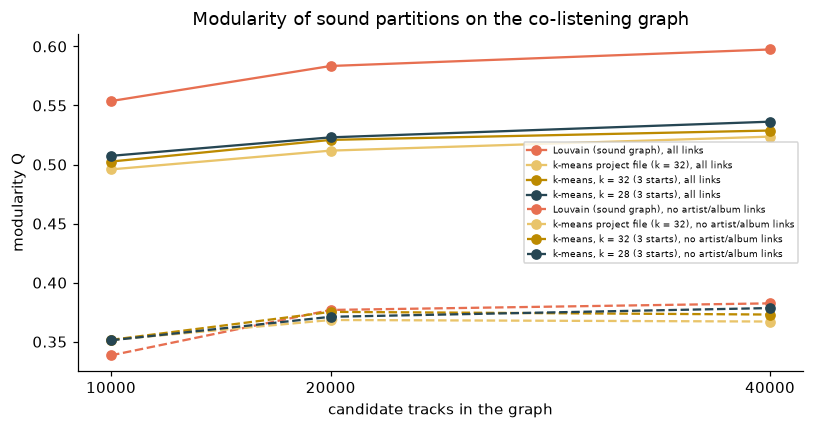

In [6]:
sens = []
for n_, g_ in graphs.items():
    Ag = g_["A"]; r2, c2 = Ag.nonzero(); w2 = np.asarray(Ag[r2, c2]).ravel(); ni = g_["node_item"]
    sa = ((item_art[ni[r2]] == item_art[ni[c2]]) & (item_art[ni[r2]] >= 0)) | ((item_alb[ni[r2]] == item_alb[ni[c2]]) & (item_alb[ni[r2]] >= 0))
    Ad = sparse.coo_matrix((w2[~sa], (r2[~sa], c2[~sa])), shape=Ag.shape).tocsr()
    sens += evaluate(Ag, g_["node_row"], n_, "all edges") + evaluate(Ad, g_["node_row"], n_, "no same-artist/album links")
sens = pd.DataFrame(sens)
st = sens.groupby(["graph", "variant", "partition"], sort=False)["Q"].mean().unstack("graph")
print(st.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(figsize=(7.5, 4))
colors = dict(zip(PARTS, [ACC, KM, "#bc8a00", REAL]))
for (var, ls) in [("all edges", "-"), ("no same-artist/album links", "--")]:
    for name in PARTS:
        y_ = st.loc[(var, name)]; ax.plot(y_.index, y_.values, "o" + ls, color=colors[name], label=f"{name}, {'all links' if var == 'all edges' else 'no artist/album links'}")
ax.set(title="Modularity of sound partitions on the co-listening graph", xlabel="candidate tracks in the graph", ylabel="modularity Q"); ax.set_xticks(N_NODES_LIST); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

### 4.1 Reading the graph size

The pattern is the same for 10,000, 20,000 and 40,000 candidate tracks. With all links Louvain is ahead by 0.05 to 0.07 (0.554 / 0.583 / 0.597 against 0.507 / 0.523 / 0.536 for k-means at k = 28). Without artist/album links the partitions lie within 0.015 of each other (0.338 to 0.382), and Louvain is slightly behind at 10,000 tracks and slightly ahead at 40,000.
In the 40,000 graph 19% of the nodes get their Louvain group from the neighbour vote (notebook 00), and the result does not change.

## 5. Louvain on the co-listening graph itself

**What we do.** We run the same own Louvain implementation (γ = 1, three seeds) directly on the co-listening graph, with all links and without same-artist/album links. Its communities are groups of tracks that are *listened to together*, found without any audio.

**Two uses.**
- **Upper reference.** Louvain maximises modularity, so its Q is close to the best any partition of this graph can reach. The ratio *Q of a sound partition / Q of the listening communities* says how much of the attainable listening structure the sound-based groups capture.
  (Louvain is a heuristic, so this is a near-maximum rather than the exact one; the ratio is therefore, if anything, slightly overstated.) The listening communities have their own number of groups; to put the sound partitions on equal footing we also report the ratio to chance.
- **Three-way agreement.** ARI and NMI between the listening communities and each sound partition, on the graph's tracks. If Louvain-on-sound agrees more with listening communities than k-means does (or less), that tells which sound partition is closer to behaviour.

Louvain on the co-listening graph (35 s):
                             groups     Q  Q_sd  ratio_to_chance  largest_group_share
variant                                                                              
all edges                   103.667 0.854 0.001           42.101                0.102
no same-artist/album links 2914.667 0.791 0.001           26.539                0.082


agreement between seeds (ARI): {'all edges': np.float64(0.511), 'no same-artist/album links': np.float64(0.523)}


                                                             Q  share_of_listening_Q  ARI_with_listening_communities  NMI_with_listening_communities
variant                    partition                                                                                                                
all edges                  Louvain (sound graph)         0.583                 0.684                           0.102                           0.336
                           k-means project file (k = 32) 0.512                 0.600                           0.103                           0.336
                           k-means, k = 32 (3 starts)    0.521                 0.610                           0.115                           0.348
                           k-means, k = 28 (3 starts)    0.523                 0.613                           0.112                           0.341
no same-artist/album links Louvain (sound graph)         0.377                 0.476                      

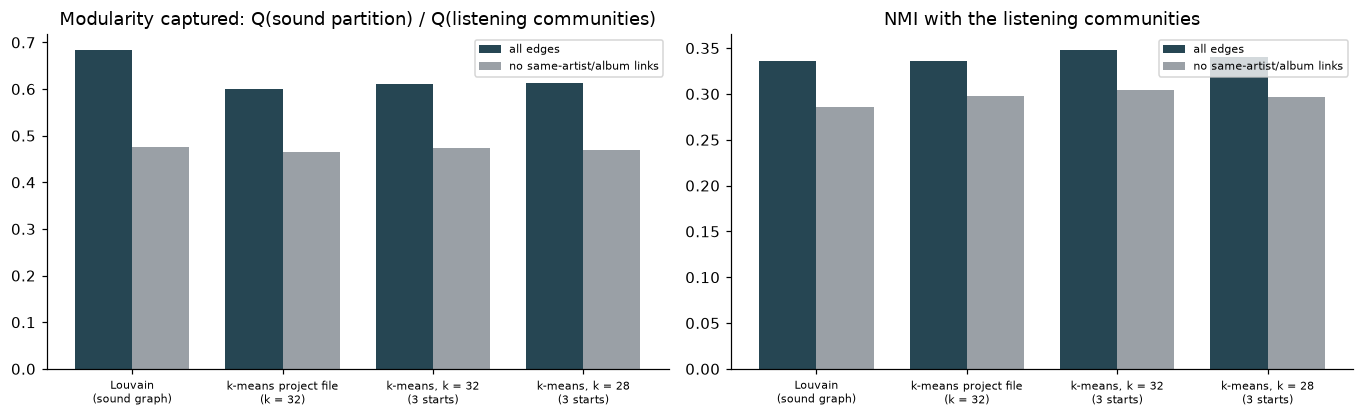

wrote RQ4_pipeline/listening_graph_modularity.csv and listening_graph_vs_listening_communities.csv


In [7]:
t0 = time.time(); lc_rows, LC = [], {}
for var, Am in [("all edges", A), ("no same-artist/album links", A_ctrl)]:
    g_l = graph_from_csr(Am)
    for s in LISTEN_SEEDS:
        r_ = LV.louvain(g_l, 1.0, s); LC[(var, s)] = r_.labels
        ins, exp_ = inside_expected(Am, r_.labels)
        lc_rows.append(dict(variant=var, seed=s, groups=r_.labels.max() + 1, Q=r_.modularity, ratio_to_chance=ins / exp_,
                            largest_group_share=np.bincount(r_.labels).max() / len(r_.labels)))
lc = pd.DataFrame(lc_rows); print(f"Louvain on the co-listening graph ({time.time() - t0:.0f} s):"); print(lc.groupby("variant").agg(groups=("groups", "mean"), Q=("Q", "mean"), Q_sd=("Q", "std"), ratio_to_chance=("ratio_to_chance", "mean"), largest_group_share=("largest_group_share", "mean")).to_string(float_format=lambda x: f"{x:.3f}"))
seed_ari_lc = {var: np.mean([ari(LC[(var, a)], LC[(var, b)]) for a in LISTEN_SEEDS for b in LISTEN_SEEDS if a < b]) for var in ["all edges", "no same-artist/album links"]}
print("agreement between seeds (ARI):", {k_: round(v, 3) for k_, v in seed_ari_lc.items()})

rows = []
for var, Qtab in [("all edges", res), ("no same-artist/album links", ctrl)]:
    Q_lc = lc[lc.variant == var].Q.mean()
    for name, runs in PARTS.items():
        rows.append(dict(variant=var, partition=name, Q=Qtab[Qtab.partition == name].Q.mean(), share_of_listening_Q=Qtab[Qtab.partition == name].Q.mean() / Q_lc,
                         ARI_with_listening_communities=np.mean([ari(LC[(var, s)], lab[node_row]) for s in LISTEN_SEEDS for lab in runs]),
                         NMI_with_listening_communities=np.mean([nmi(LC[(var, s)], lab[node_row]) for s in LISTEN_SEEDS for lab in runs])))
three = pd.DataFrame(rows).set_index(["variant", "partition"]); print(three.to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for j, var in enumerate(["all edges", "no same-artist/album links"]):
    d = three.loc[var]; x = np.arange(len(d))
    ax[0].bar(x + (j - 0.5) * 0.38, d["share_of_listening_Q"], 0.38, color=[REAL, NULL][j], label=var)
    ax[1].bar(x + (j - 0.5) * 0.38, d["NMI_with_listening_communities"], 0.38, color=[REAL, NULL][j], label=var)
for a_, t in zip(ax, ["Modularity captured: Q(sound partition) / Q(listening communities)", "NMI with the listening communities"]):
    a_.set_xticks(np.arange(len(PARTS))); a_.set_xticklabels([n.replace(" (", "\n(") for n in PARTS], fontsize=7); a_.set(title=t); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.concat([res, ctrl]).to_csv(OUT / "listening_graph_modularity.csv", index=False); three.to_csv(OUT / "listening_graph_vs_listening_communities.csv")
print("wrote RQ4_pipeline/listening_graph_modularity.csv and listening_graph_vs_listening_communities.csv")

### 5.1 Reading Louvain on the co-listening graph

**Communities found from listening alone.** Louvain on the co-listening graph finds about **104 communities** with modularity **0.854** (largest community 10% of the tracks). Without same-artist/album links it reaches 0.791. That run reports about 2,900 "groups" because removing links leaves many tracks isolated, each counted as its own group; the modularity is not affected by them.
Different seeds agree only at ARI 0.51 to 0.52, so even purely behavioural communities have soft borders.

**How much of the listening structure do sound groups capture?** Against this near-maximum, the sound partitions reach **61% (k-means) to 68% (Louvain)** of the attainable modularity with all links, and **47% (both)** without artist/album links. This answers the open question of `RQ4_extension/01`: groups defined from sound alone, never shown any listening data, capture roughly half to two thirds of the modularity that the best partition of the listening graph reaches. The rest of the listening structure follows other things (finer niches, context, language, era: none of them tested).

**Agreement with the listening communities** is modest and equal for both sound partitions: NMI 0.34 (Louvain) and 0.34 to 0.35 (k-means), ARI about 0.10 to 0.12. The listening communities are much finer (about 104 against 28 to 32 groups), which lowers ARI in particular. Neither sound partition is closer to the behavioural communities than the other.

**The briefing's Method B.** Louvain on a co-listening graph, as originally planned, gives behavioural communities that are clearly *related* to the sound groups (they share a large part of the modularity) but not the same partition. Both versions of Method B (on sound, Peter's notebook; on listening, here) now exist and point the same way.

## 6. Summary and limitations
**What this adds to RQ4.**
1. **Louvain sound groups are visible in listening behaviour, more so than the k-means pseudo-genres:** 64% of the co-listening weight lies inside Louvain groups against 58% for k-means at the same number of groups (Q 0.58 against 0.52, chance 0.00). The result is stable across graph sizes.
2. **The extra comes from artists.** Without same-artist/album links both algorithms give the same modularity (0.37 to 0.38), so for listening across artists, the genre-like structure, the choice of algorithm does not matter. Louvain's advantage is its stronger grouping of artists, which notebook 01 also found.
3. **Upper reference.** Louvain on the co-listening graph itself reaches Q = 0.85 (0.79 without artist/album links). Sound-only groups capture 61 to 68% of that with all links and 47% without artist/album links. This is the first estimate in the project of *how much* of the listening structure the sound groups explain.
4. **Behavioural communities differ from both sound partitions in detail** (NMI 0.34, about 104 communities), to the same degree for Louvain and k-means.

**Limitations.**
- The graph uses the organic stream only (5.4 million real listens, 7,702 users) and the settings of `RQ4_extension/01`, none varied here.
- Louvain is a heuristic: its modularity is a near-maximum, so the "share captured" values are, if anything, slightly too high.
- The listening communities are not reproducible across seeds in detail (ARI 0.51), so agreement with them is a coarse measure.
- The controls cover recorded metadata (artist, album) only. Associations only, in Yambda-50M.